In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv
load_dotenv(override=True)

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
data_repo_env = os.getenv("DATA_REPO_PATH")
DATA_REPO_DIR = Path(data_repo_env)

gw_stats = pd.read_csv(DATA_REPO_DIR / "GW1" / "matches.csv")
teams = pd.read_csv(DATA_REPO_DIR / "GW1" / "teams.csv")

In [3]:
corr_matrix = gw_stats[gw_stats.columns[list(range(11, 64)) + [66, 97]]].corr()

In [4]:
teams["home_xg_open_play"] = teams["code"].map(
    gw_stats.set_index("home_team")["home_xg_open_play"]
).fillna(0)
teams["away_xg_open_play"] = teams["code"].map(
    gw_stats.set_index("away_team")["away_xg_open_play"].fillna(0)
).fillna(0)

teams["home_xg_set_play"] = teams["code"].map(
    gw_stats.set_index("home_team")["home_xg_set_play"]
).fillna(0)
teams["away_xg_set_play"] = teams["code"].map(
    gw_stats.set_index("away_team")["away_xg_set_play"].fillna(0)
).fillna(0)


teams["xg_open_play"] = teams["home_xg_open_play"] + teams["away_xg_open_play"] 
teams["xg_set_play"] = teams["home_xg_set_play"] + teams["away_xg_set_play"] 
teams["xG"] = teams["xg_open_play"] + teams["xg_set_play"]
teams.drop(columns=["home_xg_open_play","away_xg_open_play","home_xg_set_play","away_xg_set_play"])

,code,id,name,short_name,strength,strength_overall_home,strength_overall_away,strength_attack_home,strength_attack_away,strength_defence_home,strength_defence_away,pulse_id,elo,fotmob_name,xg_open_play,xg_set_play,xG
0,3,1,Arsenal,ARS,NaN,4,5,0,0,0,0,1,NaN,NaN,1.62,0.26,1.88
1,7,2,Aston Villa,AVL,NaN,3,4,0,0,0,0,2,NaN,NaN,0.18,0.11,0.29
2,91,3,Bournemouth,BOU,NaN,3,3,0,0,0,0,127,NaN,NaN,0.55,0.10,0.65
3,94,4,Brentford,BRE,NaN,3,3,0,0,0,0,130,NaN,NaN,1.85,1.23,3.08
4,36,5,Brighton,BHA,NaN,2,3,0,0,0,0,131,NaN,NaN,3.54,0.22,3.76
5,8,6,Chelsea,CHE,NaN,4,4,0,0,0,0,4,NaN,NaN,1.96,0.28,2.24
6,9,7,Coventry City,COV,NaN,2,2,0,0,0,0,5,NaN,NaN,0.20,0.00,0.20
7,31,8,Crystal Palace,CRY,NaN,3,3,0,0,0,0,6,NaN,NaN,1.96,0.00,1.96
8,11,9,Everton,EVE,NaN,3,3,0,0,0,0,7,NaN,NaN,0.62,0.50,1.12
9,54,10,Fulham,FUL,NaN,2,3,0,0,0,0,34,NaN,NaN,1.28,0.05,1.33


In [6]:
teams.sort_values(by=("xG"), inplace=True, ascending=False )

Text(0.5, 1.0, 'Gameweek 1: xG')

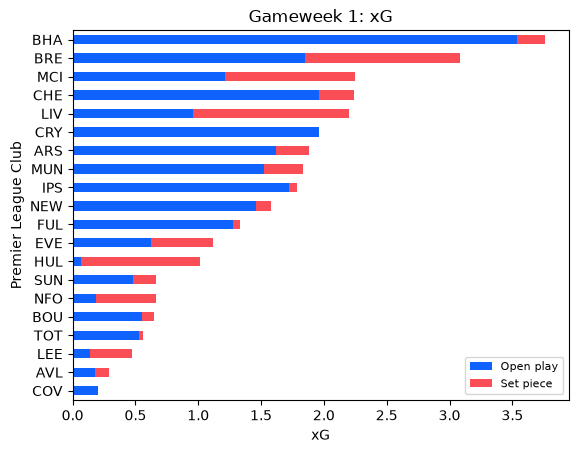

In [7]:
teams.plot(
    kind ='barh',
    x = 'short_name',
    y = ['xg_open_play','xg_set_play'],
    stacked = True,
    color = ['#0f62fe', '#fa4d56']
)
plt.gca().invert_yaxis()
plt.xlabel("xG")
plt.ylabel("Premier League Club")
plt.legend(["Open play", "Set piece"], fontsize=8, loc = 'lower right')
plt.title("Gameweek 1: xG")